<a href="https://colab.research.google.com/github/thenameisyashjoshi/Titanic-Logistic-Regression/blob/main/Titanic_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Import Libraries**

In [277]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report)

**Load Dataset**

In [278]:
df = pd.read_csv('/content/titanic.csv - titanic.csv.csv')

**Display Dataset**

In [279]:
df.head()

,PassengerId,Survived,Pclass,Name,Gender,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [280]:
df.tail()

,PassengerId,Survived,Pclass,Name,Gender,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


**Dataset Information**

In [281]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Gender       891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


**Statistical Summary**

In [282]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [283]:
df.shape

(891, 12)

**Check Missing Values**

In [284]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Gender,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


**Handle Missing Numerical Values**

In [285]:
num_imputer = SimpleImputer(strategy="median")
df[["Age"]] = num_imputer.fit_transform(df[["Age"]])

**Handle Missing Categorical Values**

In [286]:
char_imputer = SimpleImputer(strategy="most_frequent")
df[["Embarked"]] = char_imputer.fit_transform(df[["Embarked"]])

**Remove Unnecessary Features**

In [287]:
df.drop(columns = ["Cabin","PassengerId","Name","Ticket"],inplace=True)

**Verifying Missing Values**

In [288]:
df.isnull().sum()

,0
Survived,0
Pclass,0
Gender,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


**Encode Gender**

In [289]:
gender_encoder = LabelEncoder()
df["Gender"] = gender_encoder.fit_transform(df["Gender"])

**Encode Embarked**

In [290]:
df = pd.get_dummies(
    df,
    columns=["Embarked"],
)

**Display Encoded Dataset**

In [291]:
df.head()

,Survived,Pclass,Gender,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,1,22.0,1,0,7.2500,False,False,True
1,1,1,0,38.0,1,0,71.2833,True,False,False
2,1,3,0,26.0,0,0,7.9250,False,False,True
3,1,1,0,35.0,1,0,53.1000,False,False,True
4,0,3,1,35.0,0,0,8.0500,False,False,True


**Separating Features and Target**

In [292]:
X = df.drop("Survived",axis=1)
y = df["Survived"]

**Train-Test Split**

In [293]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

**Checking Dataset Shapes**

In [294]:
print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)

print("Training Labels   :", y_train.shape)
print("Testing Labels    :", y_test.shape)

Training Features : (712, 9)
Testing Features  : (179, 9)
Training Labels   : (712,)
Testing Labels    : (179,)


**Creating Logistic Regression Model**

In [295]:
model = LogisticRegression()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Displaying Predictions**

In [296]:
y_pred[:10]

array([0, 0, 0, 1, 1, 1, 1, 0, 1, 1])

**Model Accuraccy**

In [297]:
accuracy = accuracy_score(y_test,y_pred)
accuracy

0.8044692737430168

**Confusion Matrix**

In [298]:
cm = confusion_matrix(y_test,y_pred)
cm

array([[90, 15],
       [20, 54]])

**Visualizing Confusion Matrix**

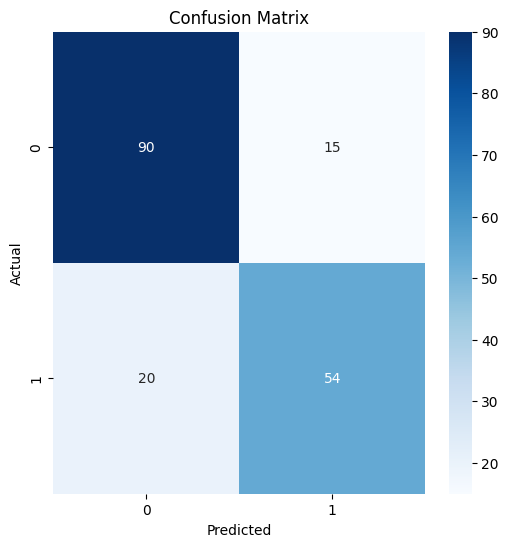

In [299]:
plt.figure(figsize=(6,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**Classification Report**

In [300]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.82      0.86      0.84       105
           1       0.78      0.73      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.80      0.80      0.80       179



**Prediction Probabilities**

In [301]:
probability = model.predict_proba(X_test)
probability[:10]

array([[0.86025377, 0.13974623],
       [0.78874143, 0.21125857],
       [0.86549019, 0.13450981],
       [0.14678881, 0.85321119],
       [0.24203628, 0.75796372],
       [0.08791899, 0.91208101],
       [0.38386633, 0.61613367],
       [0.9018577 , 0.0981423 ],
       [0.31518796, 0.68481204],
       [0.10895323, 0.89104677]])

**Comparing Actual vs Predicted**

In [302]:
comparison = pd.DataFrame({
    "Actual" : y_test,
    "Predicted" : y_pred
})
comparison.head(10)

,Actual,Predicted
709,1,0
439,0,0
840,0,0
720,1,1
39,1,1
290,1,1
300,1,1
333,0,0
208,1,1
136,1,1


**Feature Coefficients**

In [303]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})
coefficients


,Feature,Coefficient
0,Pclass,-0.813560
1,Gender,-2.496237
2,Age,-0.025234
3,SibSp,-0.244923
4,Parch,-0.122367
5,Fare,0.003229
6,Embarked_C,1.231538
7,Embarked_Q,0.682784
8,Embarked_S,0.641757


**Model Intercept**

In [304]:
print("Intercept :", model.intercept_[0])

Intercept : 2.9125882501455913


**Prediction Example**

In [307]:
sample1 = X_test.iloc[[0]]
print("Prediction : ", model.predict(sample1))
print("Probability : ", model.predict_proba(sample1))

Prediction :  [0]
Probability :  [[0.86025377 0.13974623]]


In [306]:
sample2 = X_test.iloc[[9]]
print("Prediction : ", model.predict(sample2))
print("Probability : ", model.predict_proba(sample2))

Prediction :  [1]
Probability :  [[0.10895323 0.89104677]]
